# Hamiltonian parameters of the interdigital transmon coupler

Takes the geometry from `build_design.py` (two grounded `CircTransmon`s joined by
a `CapNInterdigitalRound` coupler) and runs the full **`parametric_coupling`**
pipeline on it:

1. **Transmon parameters from the pad geometry** — `DesignHelper.circular_island_capacitance`
   -> `E_C`; target `f_01` -> `E_J`; `f_01`, anharmonicity, energy levels, ZPFs,
   junction inductance (leading-order **and** exact diagonalisation).
2. **Coupling capacitance** of the interdigital fork (coplanar-strip / elliptic-integral
   estimate — a real design gets this from a Palace LOM run).
3. **`Chip`** — an analytic Maxwell capacitance matrix -> `compute_coupling`,
   `coupling_matrix`, `print_output`; sweep `C_c` -> `J(C_c)`.
4. **Readout resonator** — `compute_cpw_geometric_parameters`, resonator length,
   `compute_Cc_from_Qc`; then `compute_dispersive_shift`, `dressed_frequencies`,
   `compute_purcell`, `compute_higher_order_dispersive`.
5. **Flux-tunable variant** — `compute_squid_EJ`, `compute_squid_phase_offset`,
   `compute_flux_tunable_frequency`, `compute_squid_inductance`; `J` vs flux.
6. **EPR / eigenmode path** — `Chip.from_eigenmode_epr` on synthetic participation
   ratios (Path B, no capacitance matrix).

> Everything analytic — no FEM is run here. The capacitance numbers are
> first-principles estimates meant to exercise the pipeline end to end.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ellipk   # ellipk(m) with m = k**2

# parametric_coupling is installed editable; add its src as a fallback
_pkg_src = os.path.abspath(os.path.join("..", "parametric_coupling_test", "src"))
if _pkg_src not in sys.path:
    sys.path.insert(0, _pkg_src)
from parametric_coupling import DesignHelper, Chip

# geometry constants from the sibling build script
from build_design import (
    PAD_RADIUS_UM, PAD_GAP_UM, CJ_Q1_FF, CJ_Q2_FF, L_Q1_NH, L_Q2_NH,
    CPL_FINGER_COUNT, CPL_FINGER_WIDTH_UM, CPL_FINGER_LENGTH_UM,
    CPL_FINGER_GAP_UM, CPL_FINGER_TIP_GAP_UM,
    _transmon_offset_um,
)

dh = DesignHelper()
u  = dh.ureg
h  = dh.planck
e  = dh.electron_charge

EPS_R  = 11.45                       # high-resistivity Si (the value the island fit was done at)
FILM_T = u.Quantity(200, "nm")       # metal thickness

print("pad radius / gap:", PAD_RADIUS_UM, "/", PAD_GAP_UM, "um")
print("fork:", CPL_FINGER_COUNT, "fingers,", CPL_FINGER_LENGTH_UM, "um long,",
      CPL_FINGER_GAP_UM, "um gap")
print("qubit half-spacing D =", round(_transmon_offset_um(), 1), "um  ->  2D =",
      round(2 * _transmon_offset_um()), "um")

pad radius / gap: 136.0 / 20.0 um
fork: 8 fingers, 80.0 um long, 4.0 um gap
qubit half-spacing D = 227.0 um  ->  2D = 454 um


## 1. Transmon parameters from the pad geometry

`circular_island_capacitance(radius, gap)` is an empirical fit to Palace
electrostatic runs for a circular island in a ground plane. Adding the junction
self-capacitance `C_j` gives the shunt capacitance `C_Sigma`, hence `E_C`.

In [2]:
C_isl = dh.circular_island_capacitance(PAD_RADIUS_UM, PAD_GAP_UM, eps_r=EPS_R)
C_j1  = u.Quantity(CJ_Q1_FF, "fF")
C_j2  = u.Quantity(CJ_Q2_FF, "fF")

def EC_from_Csigma(C_sigma):
    return (e**2 / (2.0 * C_sigma) / h).to("GHz")

C_sig1 = (C_isl + C_j1).to("fF")
C_sig2 = (C_isl + C_j2).to("fF")
EC1 = EC_from_Csigma(C_sig1)
EC2 = EC_from_Csigma(C_sig2)

print(f"island -> ground capacitance   C_isl   = {C_isl:~.2f}")
print(f"Q1 shunt capacitance           C_Sigma = {C_sig1:~.2f}   -> E_C = {EC1:~.4f}")
print(f"Q2 shunt capacitance           C_Sigma = {C_sig2:~.2f}   -> E_C = {EC2:~.4f}")

island -> ground capacitance   C_isl   = 98.28 fF
Q1 shunt capacitance           C_Sigma = 100.28 fF   -> E_C = 0.1932 GHz
Q2 shunt capacitance           C_Sigma = 100.28 fF   -> E_C = 0.1932 GHz


Fix `E_C` from the geometry, then choose a target `f_01` for each qubit and solve
for `E_J` (leading order `f01 = sqrt(8 EJ EC) - EC`). Cross-check the round trip
with `compute_transmon_frequency` in both the asymptotic and the exact
charge-basis-diagonalisation modes.

In [3]:
F01_Q1 = u.Quantity(5.00, "GHz")
F01_Q2 = u.Quantity(5.35, "GHz")

def EJ_for_target_f01(f01, EC):
    # invert f01 = sqrt(8 EJ EC) - EC  ->  EJ = (f01 + EC)^2 / (8 EC)
    return ((f01 + EC)**2 / (8.0 * EC)).to("GHz")

EJ1 = EJ_for_target_f01(F01_Q1, EC1)
EJ2 = EJ_for_target_f01(F01_Q2, EC2)

rows = []
for name, EJ, EC, f_t in [("Q1", EJ1, EC1, F01_Q1), ("Q2", EJ2, EC2, F01_Q2)]:
    ratio    = (EJ / EC).to_reduced_units().magnitude
    f_approx = dh.compute_transmon_frequency(EJ, EC).to("GHz")
    f_exact  = dh.compute_transmon_frequency(EJ, EC, exact=True).to("GHz")
    rows.append((name, f"{EJ:~.3f}", f"{EC:~.4f}", f"{ratio:.1f}",
                 f"{f_t:~}", f"{f_approx:~.4f}", f"{f_exact:~.4f}"))

import pandas as pd
display(pd.DataFrame(rows, columns=["qubit","E_J","E_C","E_J/E_C",
                                    "f01 target","f01 (asymptotic)","f01 (exact)"]))

,qubit,E_J,E_C,E_J/E_C,f01 target,f01 (asymptotic),f01 (exact)
0,Q1,17.452 GHz,0.1932 GHz,90.3,5.0 GHz,5.0000 GHz,4.9920 GHz
1,Q2,19.884 GHz,0.1932 GHz,102.9,5.35 GHz,5.3500 GHz,5.3426 GHz


Anharmonicity, spectrum, ZPFs, junction inductance.

In [4]:
rows = []
for name, EJ, EC in [("Q1", EJ1, EC1), ("Q2", EJ2, EC2)]:
    a_lo   = dh.compute_anharmonicity(EC).to("MHz")
    a_ex   = dh.compute_anharmonicity(EC, exact_EJ=EJ).to("MHz")
    phi_z, n_z = dh.compute_transmon_zpfs(EJ, EC)
    Zq     = dh.compute_transmon_impedance(EJ, EC).to("ohm")
    Lj     = dh.EJ_to_Lj(EJ).to("nH")
    lv     = dh.compute_transmon_energy_levels(EC, EJ, 4, exact=True).to("GHz").magnitude
    rows.append((name, f"{a_lo:~.2f}", f"{a_ex:~.2f}",
                 f"{phi_z.to_reduced_units().magnitude:.3f}",
                 f"{n_z.to_reduced_units().magnitude:.3f}",
                 f"{Zq:~.0f}", f"{Lj:~.2f}",
                 "  ".join(f"{x:.3f}" for x in np.diff(lv))))
display(pd.DataFrame(rows, columns=["qubit","alpha (-E_C)","alpha (exact)",
                                    "phi_zpf","n_zpf","Z_q","L_J",
                                    "f01,f12,f23 gaps (GHz)"]))

print("\nbuild_design.py places L_j =", L_Q1_NH, "nH as a placeholder; the value")
print("implied by the target f01 above is L_J(Q1) =",
      f"{dh.EJ_to_Lj(EJ1).to('nH'):~.2f}.")

,qubit,alpha (-E_C),alpha (exact),phi_zpf,n_zpf,Z_q,L_J,"f01,f12,f23 gaps (GHz)"
0,Q1,-193.16 MHz,-212.79 MHz,0.386,1.296,306 Ω,9.37 nH,4.779 4.549 4.297
1,Q2,-193.16 MHz,-211.29 MHz,0.373,1.339,286 Ω,8.22 nH,5.131 4.905 4.658



build_design.py places L_j = 10.0 nH as a placeholder; the value
implied by the target f01 above is L_J(Q1) = 9.37 nH.


The inverse design direction: pick `f_01` **and** an `E_J/E_C` ratio, get both
energies, and back out the pad radius that would give the required `C_Sigma`.

In [5]:
tgt = dh.compute_EJ_EC_from_frequency_ratio(u.Quantity(5.0, "GHz"), ratio=55, exact=True)
C_sig_needed = (e**2 / (2.0 * tgt["EC"] * h)).to("fF")
r_needed = dh.circular_island_radius_for_capacitance(
    C_sig_needed - u.Quantity(CJ_Q1_FF, "fF"), PAD_GAP_UM, eps_r=EPS_R)
g_needed = dh.circular_island_gap_for_capacitance(
    C_sig_needed - u.Quantity(CJ_Q1_FF, "fF"), PAD_RADIUS_UM, eps_r=EPS_R)
print(f"target f01 = 5.0 GHz at E_J/E_C = 55  ->  E_J = {tgt['EJ']:~.3f}, E_C = {tgt['EC']:~.4f}")
print(f"needs C_Sigma = {C_sig_needed:~.2f}")
print(f"  -> pad radius {r_needed:~.1f} at gap {PAD_GAP_UM} um")
print(f"  -> or gap     {g_needed:~.1f} at radius {PAD_RADIUS_UM} um")

target f01 = 5.0 GHz at E_J/E_C = 55  ->  E_J = 13.804 GHz, E_C = 0.2510 GHz
needs C_Sigma = 77.18 fF
  -> pad radius 107.2 µm at gap 20.0 um
  -> or gap     50.3 µm at radius 136.0 um


## 2. Interdigital coupling capacitance

No IDC model ships with `DesignHelper`, so estimate it here: each of the `N-1`
inter-finger gaps behaves like a pair of coplanar strips (width `w`, spacing
`s`), with mutual capacitance per unit length

$$C'_{\rm cs} = \varepsilon_0\,\varepsilon_{\rm eff}\;\frac{K(k')}{K(k)},\qquad
  k=\frac{s}{s+2w},\quad k'=\sqrt{1-k^2},\quad
  \varepsilon_{\rm eff}=\tfrac{1+\varepsilon_r}{2}.$$

$C_c \approx (N-1)\,\ell_{\rm overlap}\,C'_{\rm cs}$ with
$\ell_{\rm overlap}=\ell_{\rm finger}-\ell_{\rm tip\ gap}$.

This conformal-mapping estimate takes the full strip-to-strip mutual capacitance
(no fringing cutoff, thick-substrate $\varepsilon_{\rm eff}$) so it runs a bit
high; a real design gets $C_c$ from a Palace LOM (`cap_sim`) run. It is used here
only to give the `Chip` pipeline a physically-scaled number — the `J` vs `C_c`
sweep below shows the sensitivity.

In [6]:
def coplanar_strip_C_per_len(w_um, s_um, eps_r):
    '''Mutual capacitance per unit length of two coplanar strips (F/m).'''
    eps0 = u.Quantity(1, "vacuum_permittivity").to("F/m").magnitude
    eps_eff = 0.5 * (1.0 + eps_r)
    k  = s_um / (s_um + 2.0 * w_um)
    kp = np.sqrt(1.0 - k**2)
    return eps0 * eps_eff * ellipk(kp**2) / ellipk(k**2)

def idc_coupling_capacitance(n_fingers, finger_len_um, finger_w_um,
                             finger_gap_um, tip_gap_um, eps_r):
    l_overlap_m = (finger_len_um - tip_gap_um) * 1e-6
    c_per_len   = coplanar_strip_C_per_len(finger_w_um, finger_gap_um, eps_r)
    return u.Quantity((n_fingers - 1) * l_overlap_m * c_per_len, "F").to("fF")

C_c = idc_coupling_capacitance(CPL_FINGER_COUNT, CPL_FINGER_LENGTH_UM,
                               CPL_FINGER_WIDTH_UM, CPL_FINGER_GAP_UM,
                               CPL_FINGER_TIP_GAP_UM, EPS_R)
print(f"coplanar-strip C' = {coplanar_strip_C_per_len(CPL_FINGER_WIDTH_UM, CPL_FINGER_GAP_UM, EPS_R)*1e15/1e6:.3f} fF/um")
print(f"estimated interdigital coupling capacitance  C_c = {C_c:~.2f}")
print(f"  ( {(C_c / C_isl).to_reduced_units().magnitude*100:.0f}% of the island self-capacitance"
      f"  ->  expect very strong coupling, matching the ultrastrong design intent )")

coplanar-strip C' = 0.105 fF/um
estimated interdigital coupling capacitance  C_c = 54.27 fF
  ( 55% of the island self-capacitance  ->  expect very strong coupling, matching the ultrastrong design intent )


## 3. `Chip`: Maxwell capacitance matrix -> qubit-qubit coupling

Nodes `[Q1_island, Q2_island]` -- **ground is the implicit reference** (a
capacitance matrix that includes the ground row/column is singular, so `Chip`
takes the reduced form). The junction self-capacitance shunts each island to
ground, so it adds to that island's diagonal; `E_C` is then read back
self-consistently from `1/Cinv[island,island]`.

In [7]:
def maxwell_matrix(caps_to_ground, mutuals, labels):
    '''Reduced Maxwell capacitance matrix (Farads), ground = implicit reference.
    caps_to_ground {label: C_to_ground}; mutuals {(a,b): C_ab}.'''
    idx = {l: i for i, l in enumerate(labels)}
    M = np.zeros((len(labels), len(labels)))
    for l, C in caps_to_ground.items():
        M[idx[l], idx[l]] += C.to("F").magnitude
    for (a, b), C in mutuals.items():
        Cf = C.to("F").magnitude
        M[idx[a], idx[a]] += Cf; M[idx[b], idx[b]] += Cf
        M[idx[a], idx[b]] -= Cf; M[idx[b], idx[a]] -= Cf
    return M

def make_chip(mutuals, res_specs=(), c_c_islands=None):
    '''Build the qubit(+resonator) Chip and retune each junction so f01 stays
    on target given the *actual* shunt capacitance the matrix implies
    (C_Sigma,eff = 1/Cinv[i,i], which includes the coupler + resonator loading).'''
    labels = ["Q1_isl", "Q2_isl"] + [r["nodes"][0] for r in res_specs]
    ctg = {"Q1_isl": (C_isl + C_j1), "Q2_isl": (C_isl + C_j2)}
    for r in res_specs:
        ctg[r["nodes"][0]] = r["_C_to_ground"]
    M = maxwell_matrix(ctg, mutuals, labels)
    specs = [
        {"type": "qubit", "name": "Q1", "nodes": ["Q1_isl"], "EJ": EJ1, "EC": EC1},
        {"type": "qubit", "name": "Q2", "nodes": ["Q2_isl"], "EJ": EJ2, "EC": EC2},
    ] + [{k: v for k, v in r.items() if not k.startswith("_")} for r in res_specs]
    ch = Chip.from_simulation(dh, M, labels, specs)
    cinv = ch.cinv.to("1/fF").magnitude
    for name, node, f_t in [("Q1", "Q1_isl", F01_Q1), ("Q2", "Q2_isl", F01_Q2)]:
        EC_eff = EC_from_Csigma(u.Quantity(1.0 / cinv[labels.index(node), labels.index(node)], "fF"))
        ch.update_component(name, EC=EC_eff, EJ=EJ_for_target_f01(f_t, EC_eff))
    return ch, M, labels

chip, Cmat, labels = make_chip({("Q1_isl", "Q2_isl"): C_c})
print("reduced Maxwell C matrix (fF):")
print(np.array2string(Cmat * 1e15, precision=2, suppress_small=True))
for name in ("Q1", "Q2"):
    print(f"{name}: E_C,eff = {chip.components[name].EC.to('GHz'):~.4f}  "
          f"(vs geometric {EC1:~.4f})")
print("\nCinv  (1/fF):")
print(np.array2string(chip.cinv.to("1/fF").magnitude, precision=4, suppress_small=True))

reduced Maxwell C matrix (fF):
[[154.54 -54.27]
 [-54.27 154.54]]
Q1: E_C,eff = 0.1430 GHz  (vs geometric 0.1932 GHz)
Q2: E_C,eff = 0.1430 GHz  (vs geometric 0.1932 GHz)

Cinv  (1/fF):
[[0.0074 0.0026]
 [0.0026 0.0074]]


In [8]:
g12 = chip.compute_coupling("Q1", "Q2")
print(f"charge-charge coupling         g_12 = {g12.to('MHz'):~.2f}")
print(f"                                     = {g12.to('GHz'):~.4f}")

fq1 = chip.components["Q1"].frequency().to("GHz")
fq2 = chip.components["Q2"].frequency().to("GHz")
detuning = abs(fq1 - fq2).to("MHz")
print(f"\nQ1 f01 = {fq1:~.4f}   Q2 f01 = {fq2:~.4f}   |Delta| = {detuning:~.1f}")
print(f"g/|Delta| = {(g12/ (fq1-fq2)).to_reduced_units().magnitude:.2f}   "
      f"g/f_q = {(g12/fq1).to_reduced_units().magnitude:.3f}")
print("g/f_q above ~0.1 is the ultrastrong-coupling regime.")

print("\ncoupling_matrix():")
for pair, val in chip.coupling_matrix().items():
    print(f"  {pair}: {val.to('MHz'):~.2f}")

chip.print_output("Transmon coupler - Hamiltonian parameters")

charge-charge coupling         g_12 = 466.58 MHz
                                     = 0.4666 GHz

Q1 f01 = 5.0000 GHz   Q2 f01 = 5.3500 GHz   |Delta| = 350.0 MHz
g/|Delta| = -1.33   g/f_q = 0.093
g/f_q above ~0.1 is the ultrastrong-coupling regime.

coupling_matrix():
  ('Q1', 'Q2'): 466.58 MHz

  Transmon coupler - Hamiltonian parameters

--- Components ---
name  type nodes                           EJ                            EC      frequency                  anharmonicity
  Q1 qubit   [0] 23.126362498411826 gigahertz 0.14296503247699185 gigahertz  5.0 gigahertz -0.14296503247699185 gigahertz
  Q2 qubit   [1] 26.381157970280956 gigahertz 0.14296503247699185 gigahertz 5.35 gigahertz -0.14296503247699185 gigahertz

--- Pairwise Couplings ---
component_a component_b                            g   g_MHz
         Q1          Q2 0.4665769551235774 gigahertz 466.577



### `J` vs the coupling capacitance

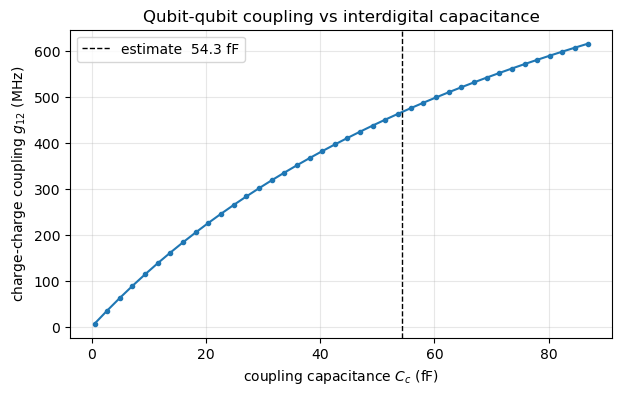

In [9]:
Cc_scan = np.linspace(0.5, float(C_c.to("fF").magnitude) * 1.6, 40)
J_scan = [make_chip({("Q1_isl", "Q2_isl"): u.Quantity(cc, "fF")})[0]
          .compute_coupling("Q1", "Q2").to("MHz").magnitude
          for cc in Cc_scan]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Cc_scan, J_scan, "-o", ms=3)
ax.axvline(float(C_c.to("fF").magnitude), color="k", ls="--", lw=1,
           label=f"estimate  {C_c.to('fF').magnitude:.1f} fF")
ax.set_xlabel("coupling capacitance $C_c$ (fF)")
ax.set_ylabel("charge-charge coupling $g_{12}$ (MHz)")
ax.set_title("Qubit-qubit coupling vs interdigital capacitance")
ax.legend(); ax.grid(alpha=.3)
plt.show()

## 4. Readout resonator and the dispersive regime

Design a $\lambda/4$ CPW readout for Q1: geometry -> `Z_0`, phase velocity ->
length, `compute_Cc_from_Qc` for a target `Q_c`. Then add it to the chip as a
third node and evaluate `chi`, dressed frequencies, Purcell limit, and the
4th-order dispersive corrections.

In [10]:
CPW_W, CPW_G = 10.0, 6.0   # um
geo = dh.compute_cpw_geometric_parameters(CPW_W, CPW_G, FILM_T, EPS_R)
v_ph = geo["v"].to("m/s")
print(f"CPW: Z0 = {geo['Z0']:~.1f}   eps_eff = {geo['eps_eff']:.3f}   v = {v_ph:~.3e}")

F_R = u.Quantity(6.6, "GHz")
# lambda/4 physical length using the CPW phase velocity (NOT vacuum c)
L_res = (v_ph / (4.0 * F_R)).to("mm")
# for comparison, the DesignHelper helper (uses vacuum c -> needs an effective ratio)
L_res_helper = dh.compute_resonator_length(F_R, 4.0 * np.sqrt(geo["eps_eff"])).to("mm")
print(f"lambda/4 length @ {F_R}:  {L_res:~.3f}   "
      f"(compute_resonator_length with eff. ratio: {L_res_helper:~.3f})")

Qc_target = 8.0e3
Cc_read = dh.compute_Cc_from_Qc(CPW_W, CPW_G, FILM_T, EPS_R, L_res, Qc_target,
                               Z0_line=50.0, wavelength_ratio=0.25)
qc_check = dh.compute_resonator_Qc_from_Cc(CPW_W, CPW_G, FILM_T, EPS_R, L_res,
                                           Cc_read, Z0_line=50.0, wavelength_ratio=0.25)
print(f"\nfor Q_c = {Qc_target:.0f}:  C_c(feedline) = {Cc_read:~.3f}")
print(f"round-trip check: Q_c = {qc_check['Qc']:.0f}, kappa/2pi = {qc_check['kappa'].to('kHz'):~.1f}, "
      f"f_r = {qc_check['frequency'].to('GHz'):~.4f}")

# lumped model for the resonator node: half the total CPW capacitance
C_res = (0.5 * geo["Cg"] * L_res).to("fF")
print(f"lumped resonator capacitance C_r = {C_res:~.1f}")

CPW: Z0 = 49.8 Ω   eps_eff = 6.034   v = 1.220e+08 m / s
lambda/4 length @ 6.6 gigahertz:  4.623 mm   (compute_resonator_length with eff. ratio: 4.623 mm)

for Q_c = 8000:  C_c(feedline) = 6.769 fF
round-trip check: Q_c = 8000, kappa/2pi = 825.0 kHz, f_r = 6.6000 GHz
lumped resonator capacitance C_r = 380.0 fF


In [11]:
# resonator couples to Q1's island with a small pad-to-pad capacitance
C_r_q1 = u.Quantity(12.0, "fF")

chip4, Cmat3, labels3 = make_chip(
    mutuals={("Q1_isl", "Q2_isl"): C_c, ("Q1_isl", "R1_pad"): C_r_q1},
    res_specs=[{"type": "resonator", "name": "R1", "nodes": ["R1_pad"],
                "frequency": F_R, "capacitance": C_res, "kappa": qc_check["kappa"],
                "_C_to_ground": C_res}],
)

print("g_Q1-R1 =", f"{chip4.compute_coupling('Q1', 'R1').to('MHz'):~.2f}")
print("g_Q2-R1 =", f"{chip4.compute_coupling('Q2', 'R1').to('MHz'):~.2f}")
print("g_Q1-Q2 =", f"{chip4.compute_coupling('Q1', 'Q2').to('MHz'):~.2f}")

chi = chip4.compute_dispersive_shift("Q1", "R1")
print(f"\ndispersive shift chi(Q1,R1) = {chi.to('MHz'):~.3f}   (2 chi = {(2*chi).to('MHz'):~.3f})")

ho = chip4.compute_higher_order_dispersive("Q1", "R1")
print("higher-order:", {k: (f"{v.to('kHz'):~.2f}" if hasattr(v, "to") else v)
                        for k, v in ho.items()})

pur = chip4.compute_purcell("Q1", "R1")
print("Purcell:", {k: (round(v, 3) if isinstance(v, float) else f"{v.to('kHz'):~.2f}")
                    for k, v in pur.items()})

chip4.print_output("Two transmons + readout resonator")

g_Q1-R1 = 71.58 MHz
g_Q2-R1 = 25.07 MHz
g_Q1-Q2 = 449.40 MHz

dispersive shift chi(Q1,R1) = 0.287 MHz   (2 chi = 0.574 MHz)
higher-order: {'chi': '287.11 kHz', 'chi_prime': '-51.49 kHz', 'vacuum_shift_res': '-6.41 kHz', 'vacuum_shift_q': '6.41 kHz', 'is_dispersive_valid': np.True_, 'dispersive_ratio': 0.04473479424288123}
Purcell: {'gamma_purcell': '1.65 kHz', 'T1_purcell_s': np.float64(0.0), 'T1_purcell_us': np.float64(96.4), 'dispersive_ratio': 0.045}

  Two transmons + readout resonator

--- Components ---
name      type nodes                           EJ                            EC      frequency                  anharmonicity
  Q1     qubit   [0]  25.00165264617512 gigahertz  0.1316610205878186 gigahertz  5.0 gigahertz  -0.1316610205878186 gigahertz
  Q2     qubit   [1] 26.627355711822283 gigahertz 0.14157130214567443 gigahertz 5.35 gigahertz -0.14157130214567443 gigahertz
  R1 resonator   [2]                         None                          None  6.6 gigahertz             

## 5. Flux-tunable Q2

Replace Q2's single junction with an asymmetric SQUID loop (`EJ1`, `EJ2`), keeping
the same island geometry. Sweep the flux and watch `f_01`, the SQUID inductance,
the potential's phase offset, and the qubit-qubit coupling `J` track it.

SQUID junctions: EJ1 = 10.936 GHz, EJ2 = 12.924 GHz, asymmetry d = 0.083
EJ(flux=0) = 23.860 GHz   EJ(flux=0.5) = 1.9884 GHz


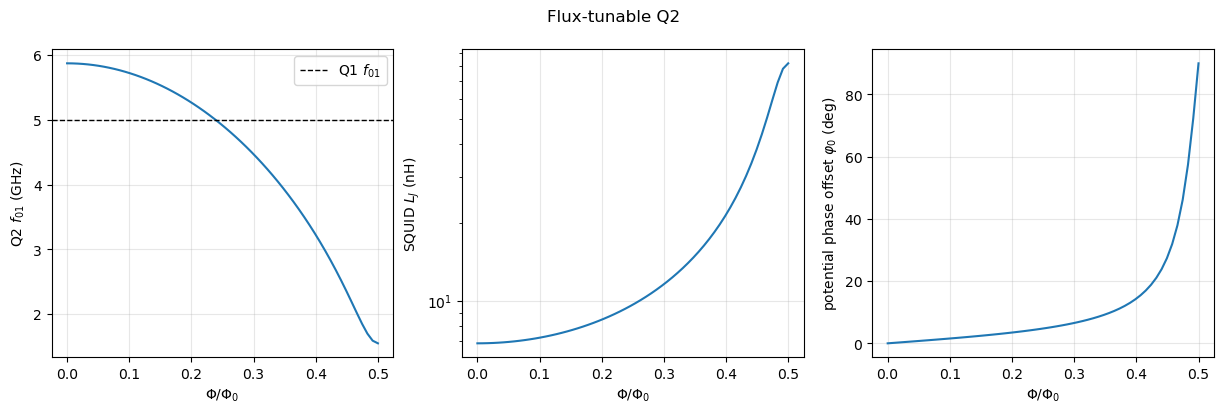

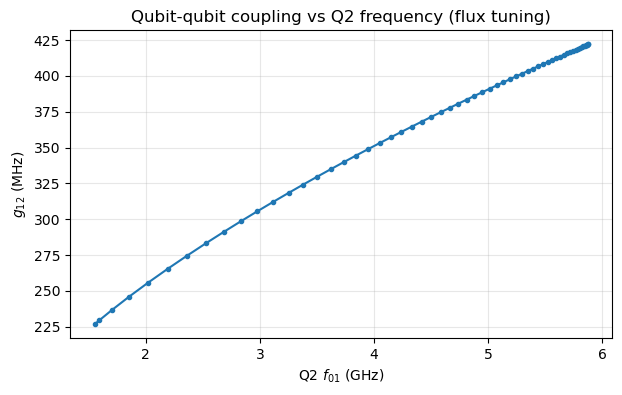

compute_flux_tunable_frequency @ flux=0.25: 4.9137 GHz


In [12]:
EJ2a = u.Quantity(float(EJ2.to("GHz").magnitude) * 0.55, "GHz")
EJ2b = u.Quantity(float(EJ2.to("GHz").magnitude) * 0.65, "GHz")
d_asym = abs(EJ2b - EJ2a) / (EJ2a + EJ2b)
print(f"SQUID junctions: EJ1 = {EJ2a:~.3f}, EJ2 = {EJ2b:~.3f}, "
      f"asymmetry d = {d_asym.to_reduced_units().magnitude:.3f}")
print(f"EJ(flux=0) = {dh.compute_squid_EJ(EJ2a, EJ2b, 0.0):~.3f}   "
      f"EJ(flux=0.5) = {dh.compute_squid_EJ(EJ2a, EJ2b, 0.5):~.4f}")

flux = np.linspace(0.0, 0.5, 60)
f01_flux, LJ_flux, phi0_flux, J_flux = [], [], [], []
for phi in flux:
    EJf = dh.compute_squid_EJ(EJ2a, EJ2b, phi)
    f01_flux.append(dh.compute_transmon_frequency(EJf, EC2, exact=True).to("GHz").magnitude)
    LJ_flux.append(dh.compute_squid_inductance(EJ2a, EJ2b, phi).to("nH").magnitude)
    phi0_flux.append(dh.compute_squid_phase_offset(EJ2a, EJ2b, phi))
    chip.update_component("Q2", EJ=EJf, EC=EC2)
    J_flux.append(chip.compute_coupling("Q1", "Q2").to("MHz").magnitude)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(flux, f01_flux); ax[0].set_xlabel(r"$\Phi/\Phi_0$"); ax[0].set_ylabel("Q2 $f_{01}$ (GHz)")
ax[0].axhline(fq1.magnitude, color="k", ls="--", lw=1, label="Q1 $f_{01}$"); ax[0].legend()
ax[1].plot(flux, LJ_flux); ax[1].set_xlabel(r"$\Phi/\Phi_0$"); ax[1].set_ylabel(r"SQUID $L_J$ (nH)")
ax[1].set_yscale("log")
ax[2].plot(flux, np.degrees(phi0_flux)); ax[2].set_xlabel(r"$\Phi/\Phi_0$")
ax[2].set_ylabel(r"potential phase offset $\varphi_0$ (deg)")
for a in ax: a.grid(alpha=.3)
fig.suptitle("Flux-tunable Q2")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(f01_flux, J_flux, "-o", ms=3)
ax.set_xlabel("Q2 $f_{01}$ (GHz)"); ax.set_ylabel("$g_{12}$ (MHz)")
ax.set_title("Qubit-qubit coupling vs Q2 frequency (flux tuning)")
ax.grid(alpha=.3); plt.show()

# restore Q2 to its fixed-junction value
_ = chip.update_component("Q2", EJ=EJ2, EC=EC2)

# compute_flux_tunable_frequency does the EJ(flux)->f01 chain in one call:
print("compute_flux_tunable_frequency @ flux=0.25:",
      f"{dh.compute_flux_tunable_frequency(EJ2a, EJ2b, EC2, 0.25, exact=True).to('GHz'):~.4f}")

## 6. EPR / eigenmode route (`Chip.from_eigenmode_epr`)

Path B never builds a capacitance matrix — it consumes participation ratios +
complex eigenfrequencies from a Palace eigenmode+EPR run. Here with **synthetic**
participation ratios just to show the call and its output.

In [13]:
# synthetic: mode 0 ~ qubit-like (high junction participation), mode 1 ~ cavity-like
participation = np.array([
    [0.93, 0.02],   # mode 0, ports [JJ, other]
    [0.05, 0.90],   # mode 1
])
eigenfreqs_hz = np.array([5.0e9, 7.2e9])
Lj_sim = dh.EJ_to_Lj(EJ1)   # nH

epr = Chip.from_eigenmode_epr(dh, participation, eigenfreqs_hz, Lj_sim,
                              qubit_idx=0, cavity_idx=1)
for k, v in epr.items():
    if not hasattr(v, "to"):
        print(f"  {k:26s} {v:.4f}")
    elif v.dimensionality == u.Quantity(1, "Hz").dimensionality:
        print(f"  {k:26s} {v.to('MHz'):~.3f}")
    else:
        print(f"  {k:26s} {v:~.3f}")

# and populate a Chip from those params (from_epr_params)
chip_epr = Chip.from_epr_params(dh, epr, qubit_name="Q1_epr", resonator_name="R1_epr")
chip_epr.print_output("Chip from EPR params")

  Ej                         17452.030 MHz
  Ec                         154.871 MHz
  Ej_over_Ec                 112.6876
  Lj                         9.366 nH
  qubit_frequency            4857.119 MHz
  qubit_frequency_linear     5000.000 MHz
  qubit_anharmonicity        154.871 MHz
  cavity_frequency           7211.062 MHz
  cavity_frequency_linear    7200.000 MHz
  cavity_anharmonicity       0.928 MHz
  chi                        23.980 MHz
  g                          644.783 MHz
  g_rwa                      175.261 MHz
  detuning                   2353.943 MHz
  P_qubit                    0.9300
  P_qubit_normalized         0.9490
  P_cav                      0.0500
  P_cav_normalized           0.0510
  phi_zpf_sq                 0.2664

  Chip from EPR params

--- Components ---
  name      type nodes                           EJ                           EC                    frequency                 anharmonicity
Q1_epr     qubit   [0] 17.452029821001048 gigahertz 0.1548709535

## Summary

In [14]:
print(f"Geometry:  pads r={PAD_RADIUS_UM} um / gap={PAD_GAP_UM} um,  "
      f"fork {CPL_FINGER_COUNT}x{CPL_FINGER_LENGTH_UM} um,  2D={2*_transmon_offset_um():.0f} um")
print(f"C_isl = {C_isl:~.1f}   C_c(est) = {C_c:~.1f}   "
      f"E_C ~ {EC1:~.3f}   E_J(Q1) ~ {EJ1:~.2f}")
print(f"f01: Q1 = {fq1:~.3f}, Q2 = {fq2:~.3f}")
print(f"qubit-qubit coupling  g_12 = {g12.to('MHz'):~.1f}   (g/f_q = "
      f"{(g12/fq1).to_reduced_units().magnitude:.2f}, ultrastrong)")
print(f"readout: f_r = {F_R}, chi = {chi.to('MHz'):~.2f}, "
      f"T1_Purcell = {pur['T1_purcell_us']:.1f} us")

Geometry:  pads r=136.0 um / gap=20.0 um,  fork 8x80.0 um,  2D=454 um
C_isl = 98.3 fF   C_c(est) = 54.3 fF   E_C ~ 0.193 GHz   E_J(Q1) ~ 17.45 GHz
f01: Q1 = 5.000 GHz, Q2 = 5.350 GHz
qubit-qubit coupling  g_12 = 466.6 MHz   (g/f_q = 0.09, ultrastrong)
readout: f_r = 6.6 gigahertz, chi = 0.29 MHz, T1_Purcell = 96.4 us
